In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, PrecisionRecallDisplay)
from src.models import get_models

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

X_train, y_train = train.drop(columns=["Churn"]), train["Churn"]
X_test, y_test = test.drop(columns=["Churn"]), test["Churn"]

models = get_models(X_train)
list(models)

['Logistic Regression', 'Decision Tree (depth 5)', 'Random Forest', 'XGBoost']

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "accuracy": "accuracy",
}

cv_results = {}
for name, pipe in models.items():
    cv_results[name] = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    print("done:", name)

done: Logistic Regression
done: Decision Tree (depth 5)
done: Random Forest
done: XGBoost


In [3]:
mean_table = pd.DataFrame({
    name: {m: r[f"test_{m}"].mean() for m in scoring}
    for name, r in cv_results.items()
}).T.round(3)

std_table = pd.DataFrame({
    name: {m: r[f"test_{m}"].std() for m in scoring}
    for name, r in cv_results.items()
}).T.round(3)

print("Mean over 5 folds:")
display(mean_table.sort_values("roc_auc", ascending=False))
print("Standard deviation over 5 folds:")
display(std_table)

Mean over 5 folds:


,roc_auc,recall,precision,f1,accuracy
Logistic Regression,0.846,0.543,0.654,0.593,0.802
XGBoost,0.843,0.524,0.653,0.581,0.800
Decision Tree (depth 5),0.829,0.540,0.618,0.574,0.789
Random Forest,0.827,0.487,0.634,0.551,0.789


Standard deviation over 5 folds:


,roc_auc,recall,precision,f1,accuracy
Logistic Regression,0.012,0.041,0.028,0.030,0.012
Decision Tree (depth 5),0.011,0.049,0.027,0.029,0.010
Random Forest,0.011,0.023,0.033,0.025,0.012
XGBoost,0.011,0.032,0.032,0.031,0.014


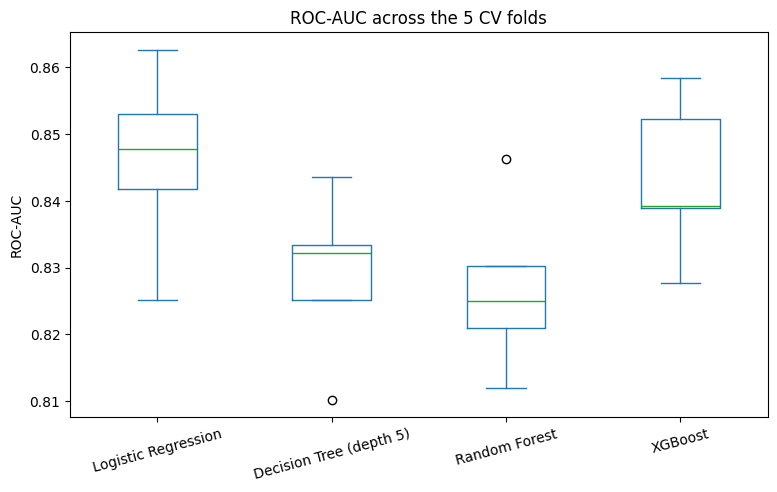

In [4]:
auc_folds = pd.DataFrame({name: r["test_roc_auc"] for name, r in cv_results.items()})

auc_folds.plot(kind="box", figsize=(9, 5), rot=15)
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC across the 5 CV folds")
plt.show()

In [5]:
final_name = "Logistic Regression"
final_model = models[final_name]
final_model.fit(X_train, y_train)

proba = final_model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"{final_name} on the held-out test set")
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall:", round(recall_score(y_test, pred), 3))
print("F1:", round(f1_score(y_test, pred), 3))

Logistic Regression on the held-out test set
ROC-AUC: 0.842
Precision: 0.654
Recall: 0.556
F1: 0.601


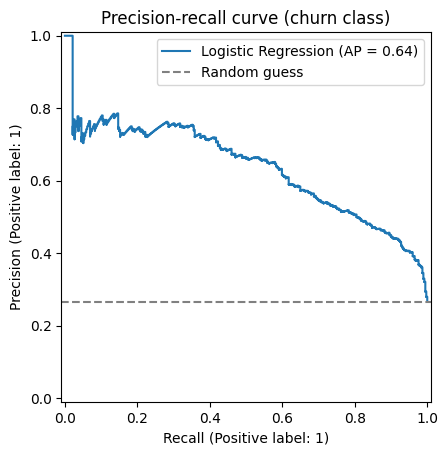

In [6]:
PrecisionRecallDisplay.from_predictions(y_test, proba, name=final_name)
plt.axhline(y_test.mean(), color="grey", linestyle="--", label="Random guess")
plt.legend()
plt.title("Precision-recall curve (churn class)")
plt.show()

In [7]:
rows = []
for t in [0.5, 0.4, 0.35, 0.3, 0.25, 0.2]:
    p = (proba >= t).astype(int)
    rows.append({
        "threshold": t,
        "customers flagged": int(p.sum()),
        "precision": precision_score(y_test, p),
        "recall": recall_score(y_test, p),
        "F1": f1_score(y_test, p),
    })

pd.DataFrame(rows).round(3)

,threshold,customers flagged,precision,recall,F1
0,0.50,318,0.654,0.556,0.601
1,0.40,439,0.572,0.671,0.617
2,0.35,484,0.545,0.706,0.615
3,0.30,542,0.522,0.757,0.618
4,0.25,607,0.499,0.810,0.618
5,0.20,684,0.469,0.858,0.607


## Evaluation summary
- 5-fold CV ROC-AUC is about 0.84 for logistic regression and gradient boosting, lower for the forest and the tree.
- Differences between the top models are within the fold-to-fold spread, so they are effectively tied.
- Test-set scores match CV scores, so the model is not overfitting.
- At the default 0.5 threshold, recall for churners is only about 55%.
- Lowering the threshold raises recall a lot at the cost of precision.
- Next: handle class imbalance and tune the best model.